# 05 — Un metodo migliore del buy & hold?

Tre strategie pubblicate, con regole e parametri fissati **prima** di vedere i risultati: vedi `docs/RICERCA_STRATEGIE.md` (pre-registro, committato prima di questo notebook).

- **A. Volatility targeting** (Moreira & Muir, 2017): meno SPY quando il mercato è agitato.
- **B. Trend su 5 asset** (Faber, 2007): azioni USA, estere, titoli di Stato, immobiliare, materie prime; ognuno tenuto solo se sopra la sua media a 10 mesi.
- **C. Dual momentum** (Antonacci, 2014): l'azionario più forte tra USA ed estero, obbligazioni quando le azioni rendono meno della liquidità.

**Vince** chi ha Sharpe più alto (intervallo bootstrap al 98,3% tutto sopra zero, Bonferroni per 3 candidate) **e** perdita massima più bassa del buy & hold di SPY.

## 1. Dati

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from quantlab.allocation import dual_momentum, fixed_weights, trend_allocation, volatility_target
from quantlab.data import load_prices
from quantlab.metrics import calendar_returns, compare, sharpe_ratio
from quantlab.portfolio import daily_cash_from_yield, run_portfolio_backtest
from quantlab.scanner import bonferroni_level
from quantlab.validation import confidence_interval, sharpe_difference_bootstrap

START, END = "1993-01-29", "2026-10-01"
ASSETS = ["SPY", "EFA", "IEF", "VNQ", "DBC", "AGG"]
FABER = ["SPY", "EFA", "IEF", "VNQ", "DBC"]

raw = load_prices(ASSETS + ["^IRX"], START, END, cache_dir="../data")
prices = raw[ASSETS].dropna(how="all")
tbill = raw["^IRX"]
for name in ASSETS:
    print(f"{name:4} from {prices[name].first_valid_index().date()}")

SPY  from 1993-01-29
EFA  from 2001-08-27
IEF  from 2002-07-30
VNQ  from 2004-09-29
DBC  from 2006-02-06
AGG  from 2003-09-29


## 2. Le decisioni di ogni strategia

Ogni fine mese, solo con i dati di quel giorno.

In [2]:
def rules(prices, vol_target=0.15, trend_months=10, momentum_months=12):
    """Target weights of the three candidates and of the references (parameters as pre-registered by default)."""
    return {
        "A_vol_target": volatility_target(prices["SPY"].dropna(), target_vol=vol_target),
        "B_trend_5_assets": trend_allocation(prices[FABER].dropna(), months=trend_months),
        "C_dual_momentum": dual_momentum(prices[["SPY", "EFA", "AGG"]].dropna(), tbill, months=momentum_months),
        "ref_60_40": fixed_weights(prices.dropna(subset=["SPY", "IEF"]), {"SPY": 0.6, "IEF": 0.4}),
        "ref_5_assets_equal": fixed_weights(prices[FABER].dropna(), {name: 0.2 for name in FABER}),
        "buy_and_hold_SPY": fixed_weights(prices, {"SPY": 1.0}).iloc[:1],  # bought once, never touched
    }

targets = rules(prices)
# Common period: from the first month end on which every rule can decide.
first = max(t.index[0] for name, t in targets.items() if name != "buy_and_hold_SPY")
print("Common start (first decision):", first.date())
targets["C_dual_momentum"].loc[first:].idxmax(axis=1).value_counts()

Common start (first decision): 2006-11-30


SPY    143
EFA     53
AGG     43
Name: count, dtype: int64

## 3. Backtest con costi e liquidità vera (T-bill giorno per giorno)

In [3]:
px = prices.loc[first:]
cash = daily_cash_from_yield(tbill, px.index)

def backtest_all(targets, commission=0.001, slippage=0.0005):
    net = {}
    for name, t in targets.items():
        t = t.loc[first:]
        if name == "buy_and_hold_SPY":
            t = pd.DataFrame({"SPY": [1.0]}, index=[first])
        net[name] = run_portfolio_backtest(px, t, commission, slippage, cash)["net_return"]
    return pd.DataFrame(net)

def metrics(net):
    """compare() table; Sharpe on returns in excess of the real daily T-bill."""
    table = compare(dict(net.items()))
    table.loc["sharpe"] = [sharpe_ratio(net[c] - cash.reindex(net.index)) for c in net]
    return table

def show(table):
    shown = table.map("{:.1%}".format)
    shown.loc["sharpe"] = table.loc["sharpe"].map("{:.2f}".format)
    print(shown.to_string())

net = backtest_all(targets)
table = metrics(net)
print(f"{first.date()} -> {net.index[-1].date()}, T-bill average {((1 + cash).prod() ** (252 / len(cash)) - 1):.2%} a year\n")
show(table)

2006-11-30 -> 2026-09-30, T-bill average 1.54% a year

                  A_vol_target B_trend_5_assets C_dual_momentum ref_60_40 ref_5_assets_equal buy_and_hold_SPY
total_return            582.4%           167.9%          312.2%    359.9%             208.8%           681.2%
annual_return            10.2%             5.1%            7.4%      8.0%               5.9%            10.9%
annual_volatility        14.1%             7.9%           15.8%     11.0%              14.3%            19.5%
sharpe                    0.65             0.47            0.44      0.62               0.36             0.55
max_drawdown            -35.0%           -13.9%          -33.7%    -32.6%             -47.2%           -55.2%


## 4. Il verdetto pre-registrato

Sharpe: bootstrap a blocchi della differenza con il buy & hold, livello 98,3%. Più perdita massima minore.

In [4]:
level = bonferroni_level(0.95, n_tests=3)
excess = net.sub(cash, axis=0)
for name in ["A_vol_target", "B_trend_5_assets", "C_dual_momentum"]:
    samples = sharpe_difference_bootstrap(excess[name], excess["buy_and_hold_SPY"], n_samples=2000, seed=42)
    low, high = confidence_interval(samples, level)
    diff = table.loc["sharpe", name] - table.loc["sharpe", "buy_and_hold_SPY"]
    smaller_dd = table.loc["max_drawdown", name] > table.loc["max_drawdown", "buy_and_hold_SPY"]
    wins = low > 0 and smaller_dd
    print(f"{name:17} Sharpe diff {diff:+.2f} [{low:+.2f}, {high:+.2f}]  smaller drawdown: {smaller_dd}  "
          f"-> {'WINS' if wins else 'does not win'}  (ahead in {np.mean(samples > 0):.0%} of samples)")

A_vol_target      Sharpe diff +0.10 [-0.08, +0.31]  smaller drawdown: True  -> does not win  (ahead in 88% of samples)


B_trend_5_assets  Sharpe diff -0.08 [-0.50, +0.32]  smaller drawdown: True  -> does not win  (ahead in 35% of samples)


C_dual_momentum   Sharpe diff -0.12 [-0.45, +0.23]  smaller drawdown: True  -> does not win  (ahead in 19% of samples)


## 5. Solo dopo la pubblicazione (vero out-of-sample)

Gli autori non potevano conoscere questi anni.

In [5]:
PUBLISHED = {"A_vol_target": "2017-01-01", "B_trend_5_assets": "2007-01-01", "C_dual_momentum": "2014-01-01"}
for name, since in PUBLISHED.items():
    part = net.loc[since:, [name, "buy_and_hold_SPY"]]
    print(f"--- {name} since {since[:4]}")
    show(metrics(part).loc[["annual_return", "sharpe", "max_drawdown"]])

--- A_vol_target since 2017
              A_vol_target buy_and_hold_SPY
annual_return        12.9%            15.2%
sharpe                0.77             0.74
max_drawdown        -25.6%           -33.7%
--- B_trend_5_assets since 2007
              B_trend_5_assets buy_and_hold_SPY
annual_return             5.1%            10.9%
sharpe                    0.48             0.55
max_drawdown            -13.9%           -55.2%
--- C_dual_momentum since 2014
              C_dual_momentum buy_and_hold_SPY
annual_return            7.7%            13.7%
sharpe                   0.44             0.73
max_drawdown           -33.7%           -33.7%


## 6. Robustezza (dichiarata nel pre-registro, non serve a scegliere)

Costi raddoppiati e parametri vicini. Se il risultato crolla con un piccolo cambio, era fortuna.

In [6]:
checks = {"pre-registered": rules(prices), 
          "costs x2": None,
          "vol 10% / 8 months / 6 months": rules(prices, 0.10, 8, 6),
          "vol 20% / 12 months / 9 months": rules(prices, 0.20, 12, 9)}
rows = {}
for label, t in checks.items():
    result = backtest_all(targets, 0.002, 0.001) if t is None else backtest_all(t)
    rows[label] = metrics(result).loc["sharpe"]
print("Sharpe in each check:")
print(pd.DataFrame(rows).round(2).to_string())

Sharpe in each check:
                    pre-registered  costs x2  vol 10% / 8 months / 6 months  vol 20% / 12 months / 9 months
A_vol_target                  0.65      0.64                           0.64                            0.62
B_trend_5_assets              0.47      0.44                           0.49                            0.50
C_dual_momentum               0.44      0.40                           0.35                            0.33
ref_60_40                     0.62      0.62                           0.62                            0.62
ref_5_assets_equal            0.36      0.36                           0.36                            0.36
buy_and_hold_SPY              0.55      0.55                           0.55                            0.55


## 7. Crescita di 1 € e drawdown

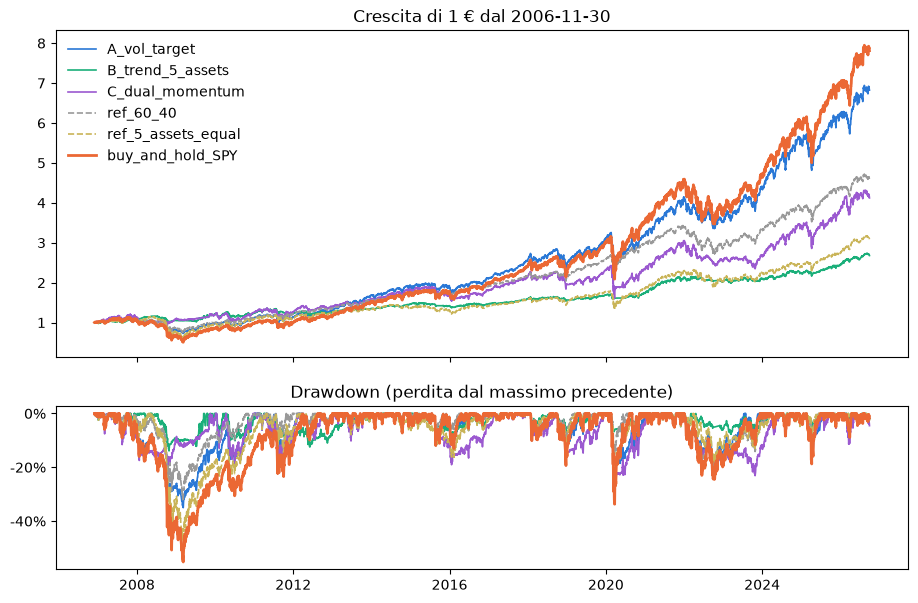

In [7]:
COLORS = {"A_vol_target": "#2a78d6", "B_trend_5_assets": "#1baf7a", "C_dual_momentum": "#9b59d0",
          "ref_60_40": "#999999", "ref_5_assets_equal": "#c9b458", "buy_and_hold_SPY": "#eb6834"}
equity = (1 + net).cumprod()
dd = equity / equity.cummax() - 1
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[2, 1])
for name in net:
    style = dict(color=COLORS[name], linewidth=2.0 if name == "buy_and_hold_SPY" else 1.2,
                 linestyle="--" if name.startswith("ref") else "-")
    top.plot(equity[name], label=name, **style)
    bottom.plot(dd[name], **style)
top.set_title(f"Crescita di 1 € dal {first.date()}")
top.legend(loc="upper left", frameon=False)
bottom.set_title("Drawdown (perdita dal massimo precedente)")
bottom.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

## 8. Anno per anno

Gli anni peggiori dicono se una strategia si riesce davvero a tenere.

In [8]:
years = pd.DataFrame({name: calendar_returns(net[name]) for name in net})
print(years.map("{:+.1%}".format).to_string())

     A_vol_target B_trend_5_assets C_dual_momentum ref_60_40 ref_5_assets_equal buy_and_hold_SPY
year                                                                                            
2006        +1.2%            -0.3%           +3.1%     +0.2%              -0.3%            +1.2%
2007        +4.1%            +8.8%          +10.0%     +7.4%              +7.6%            +5.1%
2008       -22.7%            -2.9%           -3.1%    -18.1%             -26.5%           -36.8%
2009       +19.1%           +14.3%           +8.1%    +12.6%             +19.7%           +26.4%
2010       +14.5%            +3.5%           +5.5%    +13.5%             +15.1%           +15.1%
2011        +1.6%            -0.3%           +0.3%     +7.6%              +2.4%            +1.9%
2012       +14.4%            +1.4%          +10.8%    +11.1%             +12.1%           +16.0%
2013       +31.3%            +7.7%          +15.3%    +15.6%              +7.7%           +32.3%
2014       +12.9%            +

## Conclusione

**Nessuna candidata supera il criterio pre-registrato.** Tutte riducono molto la perdita massima, ma nessuna ha uno Sharpe più alto del buy & hold in modo distinguibile dalla fortuna.

1. **A. Volatility targeting: la migliore, ma non abbastanza.** Sharpe 0,65 contro 0,55, perdita massima −35% contro −55%, rendimento quasi uguale (10,2% contro 10,9% l'anno). È avanti nell'88% dei campioni bootstrap, ma l'intervallo al 98,3% (da −0,08 a +0,31) contiene lo zero. È stabile in tutti i controlli (Sharpe tra 0,62 e 0,65) e regge anche dopo la pubblicazione (0,77 contro 0,74 dal 2017). Cede poco nei rialzi e taglia i crolli: nel 2008 −23% invece di −37%.
2. **B. Trend su 5 asset: protegge moltissimo, ma rende la metà.** Perdita massima −14% (2008: −3%), però 5,1% l'anno. Batte comunque gli stessi 5 asset tenuti fermi (0,47 contro 0,36): la regola di uscita aggiunge valore, ma il paniere di Faber (materie prime, immobiliare) è andato male in questi 20 anni.
3. **C. Dual momentum: la più deludente.** Dopo la pubblicazione Sharpe 0,44 contro 0,73, ed è fragile ai parametri (0,33–0,44). Segnale tipico di una regola che funzionava sui dati con cui è stata scoperta.
4. **Un riferimento semplicissimo fa quasi come la migliore:** il 60/40 (60% azioni, 40% titoli di Stato) ha Sharpe 0,62 e perdita massima −33%, senza nessuna regola.
5. **Una nota sul periodo:** il pre-registro diceva "da gennaio 2007", ma la prima decisione possibile è caduta il 30 novembre 2006. Differenza di un mese, dichiarata qui.

**In una frase:** in questi 20 anni nessun metodo testato batte il buy & hold di SPY in modo dimostrabile. Il volatility targeting e il 60/40 offrono quasi lo stesso rendimento per unità di rischio, con crolli molto più piccoli. Questo è un risultato di ricerca su dati passati, non un consiglio d'investimento.